# Trabajo 5 · Identificación de estrés con señales fisiológicas (WESAD)
**Entornos Inteligentes**
## Figuras para el póster de estrés

Este notebook no entrena modelos, no realiza predicciones nuevas y no modifica los CSV originales. Usa los resultados ya exportados por el notebook 01. Los gráficos se guardan en la carpeta `figuras_poster` en PNG, PDF y SVG.


In [15]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from sklearn.metrics import f1_score, matthews_corrcoef

def buscar_outputs():
    candidatas = [Path(os.environ['OUT_POSTER']).expanduser()] if os.environ.get('OUT_POSTER') else []
    cwd = Path.cwd().resolve()
    candidatas += [cwd / 'outputs', cwd / 'P3' / 'outputs', cwd.parent / 'outputs', cwd]
    for carpeta in candidatas:
        if (carpeta / 'resultados_resumen.csv').is_file():
            return carpeta.resolve()
    raise FileNotFoundError(
        'No se encontraron los CSV en outputs/. Ejecuta primero el notebook 01 o define '
        'OUT_POSTER con la carpeta que contiene resultados_resumen.csv.'
    )

ORIGEN = buscar_outputs()

DESTINO = ORIGEN.parent / 'figuras_poster'
DESTINO.mkdir(parents=True, exist_ok=True)
print('Resultados:', ORIGEN)
print('Figuras:', DESTINO)

# Colores del póster
AZUL = '#10243B'
TURQUESA = '#00A998'
AZUL_CLARO = '#7295B2'
GRIS = '#CBD5E1'
ROJO = '#C45454'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelcolor': AZUL,
    'text.color': AZUL,
    'axes.titleweight': 'bold',
    'savefig.facecolor': 'white'
})

def guardar(fig, nombre):
    for ext in ('png', 'pdf', 'svg'):
        fig.savefig(
            DESTINO / f'{nombre}.{ext}',
            bbox_inches='tight',
            dpi=300 if ext == 'png' else None
        )
    plt.show()
    plt.close(fig)

def leer(nombre):
    archivo = ORIGEN / nombre
    if not archivo.exists():
        raise FileNotFoundError(f'No se encuentra {archivo}')
    return pd.read_csv(archivo)

# Comprobar archivos
archivos = [
    'resultados_resumen.csv',
    'resultados_por_sujeto.csv',
    'OOF_best_model.csv',
    'OOF_modelos_principales.csv'
]


Resultados: /Users/marcfax/Desktop/EI/P3/outputs
Figuras: /Users/marcfax/Desktop/EI/P3/figuras_poster


## 1. Comprobación de resultados exportados


In [16]:
resumen = leer('resultados_resumen.csv')
resumen = resumen.rename(columns={resumen.columns[0]: 'Modelo'}).set_index('Modelo')

def media_metrica(serie):
    return pd.to_numeric(serie.astype(str).str.split('±', regex=False).str[0], errors='coerce')

medias = pd.DataFrame({c: media_metrica(resumen[c]) for c in resumen.columns})
print('Modelos encontrados:', list(medias.index))
display(medias[['Acc','F1','MCC','AUC']].round(3))

Modelos encontrados: ['Baseline_mayoritaria', 'Baseline_umbral_EDA', 'SVM', 'RF', 'XGBoost', 'LR', 'AdaBoost', 'KNN', 'SVM|raw', 'SVM|pers', 'RF|raw', 'RF|pers', 'XGBoost|raw', 'XGBoost|pers', 'LR|raw', 'LR|pers', 'AdaBoost|raw', 'AdaBoost|pers', 'KNN|raw', 'KNN|pers', 'Baseline_umbral_EDA|raw', 'Baseline_umbral_EDA|pers', 'RF|solo EDA', 'RF|solo HRV', 'RF|EDA+HRV', 'RF|+RESP', 'RF|+EMG', 'RF|+ACC', 'RF|+TEMP', 'RF|muñeca (EDA+BVP+TEMP)', 'LSTM', 'CNN']


,Acc,F1,MCC,AUC
Modelo,,,,
Baseline_mayoritaria,0.779,0.000,0.000,0.500
Baseline_umbral_EDA,0.584,0.184,0.057,0.904
SVM,0.904,0.697,0.695,0.928
RF,0.929,0.829,0.804,0.984
XGBoost,0.932,0.835,0.814,0.990
LR,0.887,0.737,0.723,0.971
AdaBoost,0.894,0.757,0.730,0.966
KNN,0.889,0.663,0.638,0.886
SVM|raw,0.901,0.701,0.689,0.930


## 2. Figura: comparación de modelos
Se incluyen los modelos principales que estén presentes en el CSV. La selección gráfica no altera el ranking calculado en el entrenamiento.

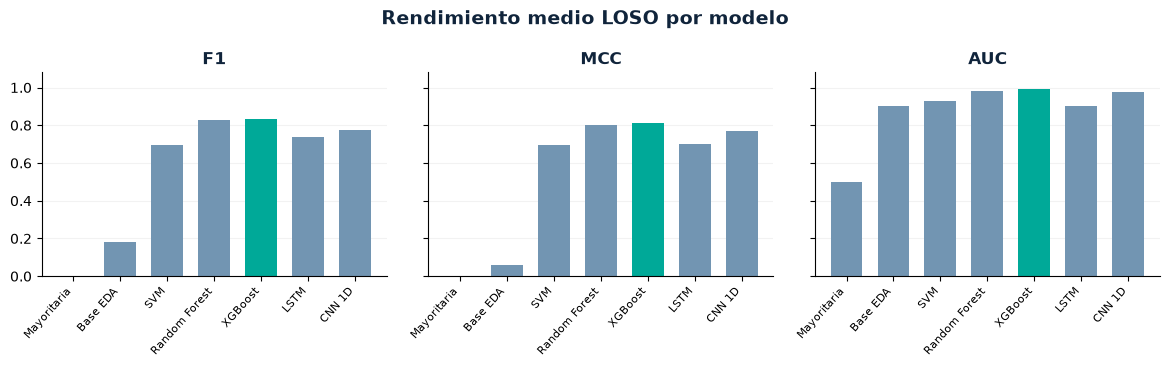

In [17]:
preferidos = ['Baseline_mayoritaria', 'Baseline_umbral_EDA', 'SVM', 'RF', 'XGBoost', 'LSTM', 'CNN']
sel = [m for m in preferidos if m in medias.index]
if not sel:
    raise ValueError('No se encontraron los modelos principales en resultados_resumen.csv')
comparacion = medias.loc[sel, ['F1', 'MCC', 'AUC']].copy()
nombres = {'Baseline_mayoritaria':'Mayoritaria', 'Baseline_umbral_EDA':'Base EDA',
           'RF':'Random Forest', 'CNN':'CNN 1D'}
fig, axs = plt.subplots(1, 3, figsize=(11.8, 3.7), sharey=True)
for ax, metrica in zip(axs, ['F1', 'MCC', 'AUC']):
    vals = comparacion[metrica].to_numpy()
    xx = np.arange(len(sel))
    colores = [TURQUESA if s == 'XGBoost' else AZUL_CLARO for s in sel]
    ax.bar(xx, vals, color=colores, width=.68)
    ax.set_xticks(xx, [nombres.get(s,s) for s in sel], rotation=48, ha='right', fontsize=8)
    ax.set_title(metrica)
    ax.set_ylim(min(-0.1, np.nanmin(vals)-0.06) if metrica=='MCC' else 0, 1.08)
    ax.grid(axis='y', alpha=.16)
    ax.set_axisbelow(True)
fig.suptitle('Rendimiento medio LOSO por modelo', fontsize=14, fontweight='bold')
fig.tight_layout()
guardar(fig, 'comparacion_modelos')

## 3. Figura: estudio de ablación
Se usan las filas `RF|...` que el entrenamiento ya calculó. No se vuelven a entrenar variantes de RF.

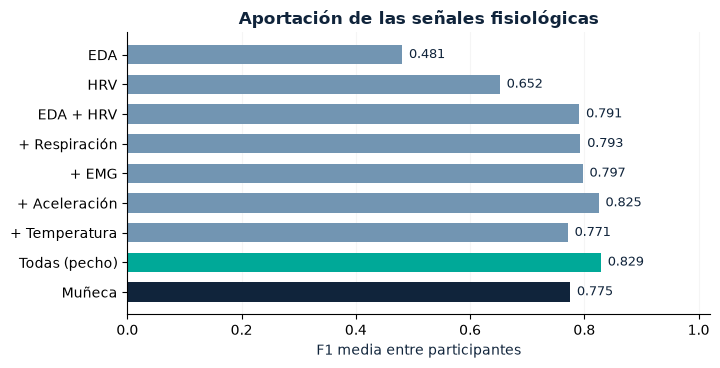

In [18]:
ablaciones = {'RF|solo EDA':'EDA', 'RF|solo HRV':'HRV', 'RF|EDA+HRV':'EDA + HRV',
             'RF|+RESP':'+ Respiración', 'RF|+EMG':'+ EMG', 'RF|+ACC':'+ Aceleración',
             'RF|+TEMP':'+ Temperatura', 'RF':'Todas (pecho)',
             'RF|muñeca (EDA+BVP+TEMP)':'Muñeca'}
filas = [(v, float(medias.loc[k, 'F1']), k) for k,v in ablaciones.items() if k in medias.index]
if not filas:
    print('No se encuentran resultados de ablación.')
else:
    etiquetas, valores, claves = zip(*filas)
    fig, ax = plt.subplots(figsize=(7.3, max(3.1, len(filas)*.42)))
    y = np.arange(len(filas))
    colores = [TURQUESA if k == 'RF' else (AZUL if 'muñeca' in k else AZUL_CLARO) for k in claves]
    ax.barh(y, valores, color=colores, height=.65)
    ax.set_yticks(y, etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.02)
    ax.set_xlabel('F1 media entre participantes')
    for yi, vi in zip(y, valores): ax.text(vi+.012, yi, f'{vi:.3f}', va='center', fontsize=9)
    ax.grid(axis='x', alpha=.12)
    ax.set_axisbelow(True)
    ax.set_title('Aportación de las señales fisiológicas')
    fig.tight_layout()
    guardar(fig, 'ablacion_senales')

## 4. Figura: variabilidad entre participantes
El mejor modelo se determina a partir del archivo OOF exportado o, si no hay metadatos en el CSV, se utiliza el modelo elegido por el notebook 01 (`XGBoost`).

Columnas: ['Subject', 'Acc', 'F1', 'MCC', 'AUC', 'Precision', 'Recall', 'Specificity', 'FPR', 'Modelo']


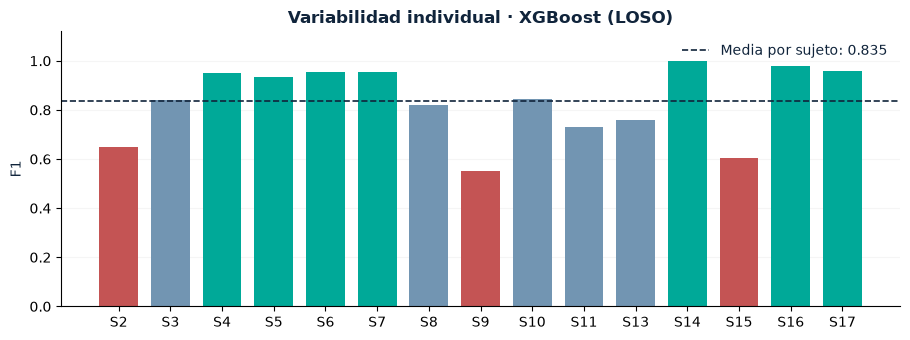

In [19]:
por_sujeto = leer('resultados_por_sujeto.csv')
print('Columnas:', list(por_sujeto.columns))
assert {'Subject','Modelo','F1'}.issubset(por_sujeto.columns), 'Formato inesperado en resultados_por_sujeto.csv'
modelo = 'XGBoost'
sub = por_sujeto.loc[por_sujeto['Modelo'] == modelo].copy()
if sub.empty:
    raise ValueError(f'No hay resultados de {modelo} en resultados_por_sujeto.csv')
sub['F1'] = pd.to_numeric(sub['F1'])
sub['n_sujeto'] = sub['Subject'].astype(str).str.extract(r'(\d+)').astype(int)
sub = sub.sort_values('n_sujeto')
fig, ax = plt.subplots(figsize=(9.2, 3.5))
colores = [ROJO if v<.7 else (TURQUESA if v>=.85 else AZUL_CLARO) for v in sub['F1']]
ax.bar(sub['Subject'], sub['F1'], color=colores, width=.75)
ax.axhline(sub['F1'].mean(), linestyle='--', color=AZUL, linewidth=1.2,
           label=f'Media por sujeto: {sub["F1"].mean():.3f}')
ax.set_ylabel('F1')
ax.set_ylim(0, 1.12)
ax.set_title('Variabilidad individual · XGBoost (LOSO)')
ax.legend(frameon=False, loc='upper right')
ax.grid(axis='y', alpha=.12)
ax.set_axisbelow(True)
fig.tight_layout()
guardar(fig, 'variabilidad_sujetos')

## 5. Figura: cobertura frente a rendimiento con abstención
Se reconstruye a partir de las **probabilidades OOF guardadas**. Es un cálculo de métricas sobre predicciones existentes, no un entrenamiento nuevo. La F1 es agregada entre ventanas aceptadas, no la media de F1 por participante.

,umbral,cobertura,F1,MCC
0,0.5,1.000,0.843,0.800
1,0.6,0.968,0.868,0.833
2,0.7,0.942,0.892,0.864
3,0.8,0.911,0.919,0.900
4,0.9,0.853,0.945,0.933


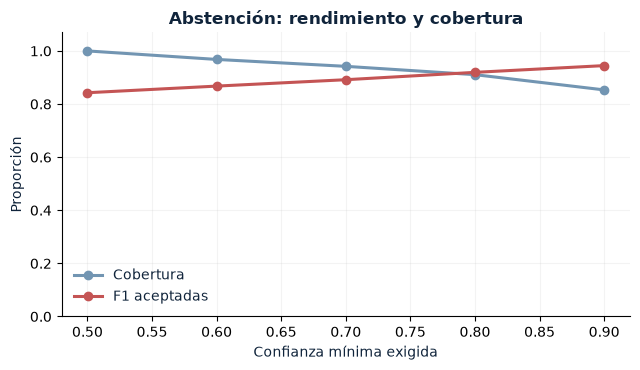

In [20]:
oof = leer('OOF_best_model.csv')
assert {'y','p'}.issubset(oof.columns), 'Se esperaban columnas y y p en OOF_best_model.csv'
y = oof['y'].to_numpy(dtype=int)
p = oof['p'].to_numpy(dtype=float)
confianza = np.maximum(p, 1-p)
filas = []
for umbral in [.5, .6, .7, .8, .9]:
    mask = confianza >= umbral
    if mask.sum() < 10 or len(np.unique(y[mask])) < 2: continue
    pred = (p[mask] >= .5).astype(int)
    filas.append((umbral, mask.mean(), f1_score(y[mask], pred, zero_division=0), matthews_corrcoef(y[mask], pred)))
curva = pd.DataFrame(filas, columns=['umbral','cobertura','F1','MCC'])
display(curva.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(curva['umbral'], curva['cobertura'], 'o-', color=AZUL_CLARO, linewidth=2.2, label='Cobertura')
ax.plot(curva['umbral'], curva['F1'], 'o-', color=ROJO, linewidth=2.2, label='F1 aceptadas')
ax.set_ylim(0, 1.07)
ax.set_xlabel('Confianza mínima exigida')
ax.set_ylabel('Proporción')
ax.set_title('Abstención: rendimiento y cobertura')
ax.grid(alpha=.15)
ax.legend(frameon=False)
fig.tight_layout()
guardar(fig, 'incertidumbre')

## 6. Figura opcional: falsas alarmas por condición
Se usa el campo `Cond` de las predicciones OOF del modelo elegido.

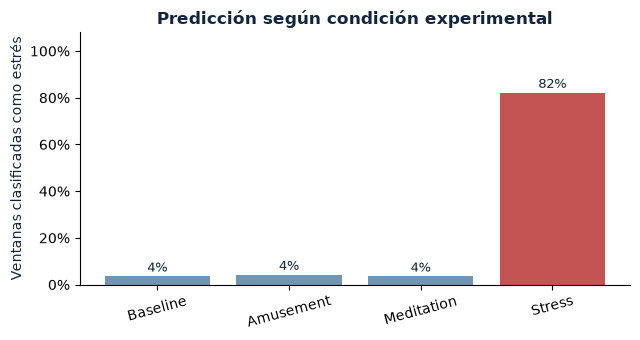

In [21]:
if 'Cond' not in oof.columns:
    print('No hay columna Cond, se omite el gráfico.')
else:
    datos = oof.assign(pred=(oof['p']>=.5).astype(int)).groupby('Cond')['pred'].agg(['mean','size'])
    orden = [s for s in ['Baseline','Amusement','Meditation','Stress'] if s in datos.index]
    datos = datos.loc[orden]
    fig, ax = plt.subplots(figsize=(6.5,3.5))
    barras = ax.bar(datos.index, datos['mean'], color=[ROJO if x=='Stress' else AZUL_CLARO for x in datos.index])
    ax.set_ylim(0,1.08)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel('Ventanas clasificadas como estrés')
    ax.set_title('Predicción según condición experimental')
    ax.tick_params(axis='x', rotation=15)
    for barra, valor in zip(barras, datos['mean']):
        ax.text(barra.get_x()+barra.get_width()/2, valor+.02, f'{valor:.0%}', ha='center', fontsize=9)
    fig.tight_layout()
    guardar(fig, 'condiciones')